In [ ]:
#librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sbn
import datetime

In [ ]:
#leo los archivos
datos01=pd.read_parquet('green_tripdata_2020-01.parquet')
datos02=pd.read_parquet('green_tripdata_2020-02.parquet')
datos03=pd.read_parquet('green_tripdata_2020-03.parquet')
datos04=pd.read_parquet('green_tripdata_2020-04.parquet')
datos05=pd.read_parquet('green_tripdata_2020-05.parquet')
datos06=pd.read_parquet('green_tripdata_2020-06.parquet')
datos07=pd.read_parquet('green_tripdata_2020-07.parquet')

In [ ]:
#nombres d elas columnas
datos01.columns=['ID Proveedor','Fecha inicio','Fecha final','Viaje memoria','Tipo cuota','Zona inicial','Zona final','Pasajeros','Distancia','Tarifa','Tarifa Extra','Impuesto','Propina','Peajes','Ehail fee','Banderazo','Total','Tipo de pago','Tipo de Viaje','Cargo por trafico']
datos02.columns=['ID Proveedor','Fecha inicio','Fecha final','Viaje memoria','Tipo cuota','Zona inicial','Zona final','Pasajeros','Distancia','Tarifa','Tarifa Extra','Impuesto','Propina','Peajes','Ehail fee','Banderazo','Total','Tipo de pago','Tipo de Viaje','Cargo por trafico']
datos03.columns=['ID Proveedor','Fecha inicio','Fecha final','Viaje memoria','Tipo cuota','Zona inicial','Zona final','Pasajeros','Distancia','Tarifa','Tarifa Extra','Impuesto','Propina','Peajes','Ehail fee','Banderazo','Total','Tipo de pago','Tipo de Viaje','Cargo por trafico']
datos04.columns=['ID Proveedor','Fecha inicio','Fecha final','Viaje memoria','Tipo cuota','Zona inicial','Zona final','Pasajeros','Distancia','Tarifa','Tarifa Extra','Impuesto','Propina','Peajes','Ehail fee','Banderazo','Total','Tipo de pago','Tipo de Viaje','Cargo por trafico']
datos05.columns=['ID Proveedor','Fecha inicio','Fecha final','Viaje memoria','Tipo cuota','Zona inicial','Zona final','Pasajeros','Distancia','Tarifa','Tarifa Extra','Impuesto','Propina','Peajes','Ehail fee','Banderazo','Total','Tipo de pago','Tipo de Viaje','Cargo por trafico']
datos06.columns=['ID Proveedor','Fecha inicio','Fecha final','Viaje memoria','Tipo cuota','Zona inicial','Zona final','Pasajeros','Distancia','Tarifa','Tarifa Extra','Impuesto','Propina','Peajes','Ehail fee','Banderazo','Total','Tipo de pago','Tipo de Viaje','Cargo por trafico']
datos07.columns=['ID Proveedor','Fecha inicio','Fecha final','Viaje memoria','Tipo cuota','Zona inicial','Zona final','Pasajeros','Distancia','Tarifa','Tarifa Extra','Impuesto','Propina','Peajes','Ehail fee','Banderazo','Total','Tipo de pago','Tipo de Viaje','Cargo por trafico']

In [ ]:
#hago un solo dataframe
datos2020=pd.DataFrame()
datos2020=pd.concat([datos01,datos02,datos03,datos04,datos05,datos06,datos07])
#copio el dataframe
datos2020_1 = datos2020.copy()

In [ ]:
#veo cuantos registros hay en mi muestra
len(datos2020)

1298271

*   Empezamos con 7 archivos en formato parquet de los primeros 7 meses del año 2020 de la data de viajes de los taxis verdes de NewYork EEUU
*   Concatenamos los 7 archivos en uno solo para mejor manipulación
*   Contamos con un total de 1,298,271 registros
*   Borramos la columna de 'Ehail fee' ya que sus datos son "None"
*   Cambiamos el nombre de las columnas a nombres de mas fácil comprensión
*   Eliminamos las columnas 'Viaje memoria','Cargo por trafico','Impuesto','Peajes','Banderazo','Distancia' por no ser representativas para el informe
*   Cambiamos en tipo cuota los valores NaN por 1 (unknown-desconocido) al igual que los 99
*   Cambiamos en tipo pago los valores NaN por 5 (unknown-desconocido)
*   Cambiamos en tipo de Viaje los valores NaN por 1 (street-hail)
*   Cambiamos en pasajeros los valores NaN por 0 (fue recogida de alguna cosa y no pasajeros)
*   Cambiamos el tipo de dato a int en las columnas 'Tipo cuota', 'Pasajeros', 'Tipo de pago', 'Tipo de Viaje'
*   Creo las dos nuevas columnas 'Hora Inicio' 'Hora Final' con base a la hora de las 'Fecha inicio' y 'Fecha final'
*   Creo la columna 'Tarfia noche' en donde pondre Y si es de noche y N el viaje fue de día
*   Obtenemos las medidas estadísticas sobre la columna de Tarifa para entender su comportamiento




In [ ]:
datos2020_1=datos2020_1.drop(columns=['Ehail fee'])
datos2020_1=datos2020_1.drop(columns=['Viaje memoria','Cargo por trafico','Impuesto','Peajes','Banderazo','Distancia'])
datos2020_1

,ID Proveedor,Fecha inicio,Fecha final,Tipo cuota,Zona inicial,Zona final,Pasajeros,Tarifa,Tarifa Extra,Propina,Total,Tipo de pago,Tipo de Viaje
0,2,2019-12-18 15:52:30,2019-12-18 15:54:39,1.0,264,264,5.0,3.50,0.50,0.01,4.81,1.0,1.0
1,2,2020-01-01 00:45:58,2020-01-01 00:56:39,5.0,66,65,2.0,20.00,0.00,4.06,24.36,1.0,2.0
2,2,2020-01-01 00:41:38,2020-01-01 00:52:49,1.0,181,228,1.0,10.50,0.50,3.54,15.34,1.0,1.0
3,1,2020-01-01 00:52:46,2020-01-01 01:14:21,1.0,129,263,2.0,21.00,3.25,0.00,25.05,2.0,1.0
4,1,2020-01-01 00:19:57,2020-01-01 00:30:56,1.0,210,150,1.0,10.00,0.50,0.00,11.30,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
72253,2,2020-07-31 23:53:00,2020-08-01 00:33:00,NaN,238,182,NaN,43.45,0.00,2.75,46.50,NaN,NaN
72254,2,2020-07-31 23:31:00,2020-07-31 23:59:00,NaN,35,51,NaN,51.76,0.00,2.75,60.93,NaN,NaN
72255,2,2020-07-31 23:12:00,2020-07-31 23:39:00,NaN,185,69,NaN,27.27,0.00,2.75,30.32,NaN,NaN
72256,2,2020-07-31 23:04:00,2020-07-31 23:15:00,NaN,241,174,NaN,13.88,0.00,2.75,16.93,NaN,NaN


In [ ]:
datos2020_1['Tipo cuota']=datos2020_1['Tipo cuota'].fillna(1)
datos2020_1

,ID Proveedor,Fecha inicio,Fecha final,Tipo cuota,Zona inicial,Zona final,Pasajeros,Tarifa,Tarifa Extra,Propina,Total,Tipo de pago,Tipo de Viaje
0,2,2019-12-18 15:52:30,2019-12-18 15:54:39,1.0,264,264,5.0,3.50,0.50,0.01,4.81,1.0,1.0
1,2,2020-01-01 00:45:58,2020-01-01 00:56:39,5.0,66,65,2.0,20.00,0.00,4.06,24.36,1.0,2.0
2,2,2020-01-01 00:41:38,2020-01-01 00:52:49,1.0,181,228,1.0,10.50,0.50,3.54,15.34,1.0,1.0
3,1,2020-01-01 00:52:46,2020-01-01 01:14:21,1.0,129,263,2.0,21.00,3.25,0.00,25.05,2.0,1.0
4,1,2020-01-01 00:19:57,2020-01-01 00:30:56,1.0,210,150,1.0,10.00,0.50,0.00,11.30,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
72253,2,2020-07-31 23:53:00,2020-08-01 00:33:00,1.0,238,182,NaN,43.45,0.00,2.75,46.50,NaN,NaN
72254,2,2020-07-31 23:31:00,2020-07-31 23:59:00,1.0,35,51,NaN,51.76,0.00,2.75,60.93,NaN,NaN
72255,2,2020-07-31 23:12:00,2020-07-31 23:39:00,1.0,185,69,NaN,27.27,0.00,2.75,30.32,NaN,NaN
72256,2,2020-07-31 23:04:00,2020-07-31 23:15:00,1.0,241,174,NaN,13.88,0.00,2.75,16.93,NaN,NaN


In [ ]:
datos2020_1["Tipo cuota"].astype(int).unique()

array([ 1,  5,  4,  2,  3, 99,  6])

In [ ]:
datos2020_1['Tipo cuota'] = datos2020_1['Tipo cuota'].replace(99.,1)

In [ ]:
#cambio el tipo de pago NaN por 5 (unknown)
datos2020_1['Tipo de pago']=datos2020_1['Tipo de pago'].fillna('5')

In [ ]:
#cambio el tipo de viaje NaN por 1 (street-hail)
datos2020_1['Tipo de Viaje']=datos2020_1['Tipo de Viaje'].fillna('1')

In [ ]:
#cambio los Pasajeros NaN por 0 (sin pasajero)
datos2020_1['Pasajeros']=datos2020_1['Pasajeros'].fillna('0')

In [ ]:
#cambio el tipo de datos a int de las columnas 'Tipo cuota', 'Pasajeros', 'Tipo de pago', 'Tipo de Viaje'
datos2020_1[['Tipo cuota', 'Pasajeros', 'Tipo de pago', 'Tipo de Viaje']] = datos2020_1[['Tipo cuota', 'Pasajeros', 'Tipo de pago', 'Tipo de Viaje']].astype(float).astype(int) #convierto a float para evitar errores de texto y luego a int
datos2020_1

,ID Proveedor,Fecha inicio,Fecha final,Tipo cuota,Zona inicial,Zona final,Pasajeros,Tarifa,Tarifa Extra,Propina,Total,Tipo de pago,Tipo de Viaje
0,2,2019-12-18 15:52:30,2019-12-18 15:54:39,1,264,264,5,3.50,0.50,0.01,4.81,1,1
1,2,2020-01-01 00:45:58,2020-01-01 00:56:39,5,66,65,2,20.00,0.00,4.06,24.36,1,2
2,2,2020-01-01 00:41:38,2020-01-01 00:52:49,1,181,228,1,10.50,0.50,3.54,15.34,1,1
3,1,2020-01-01 00:52:46,2020-01-01 01:14:21,1,129,263,2,21.00,3.25,0.00,25.05,2,1
4,1,2020-01-01 00:19:57,2020-01-01 00:30:56,1,210,150,1,10.00,0.50,0.00,11.30,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
72253,2,2020-07-31 23:53:00,2020-08-01 00:33:00,1,238,182,0,43.45,0.00,2.75,46.50,5,1
72254,2,2020-07-31 23:31:00,2020-07-31 23:59:00,1,35,51,0,51.76,0.00,2.75,60.93,5,1
72255,2,2020-07-31 23:12:00,2020-07-31 23:39:00,1,185,69,0,27.27,0.00,2.75,30.32,5,1
72256,2,2020-07-31 23:04:00,2020-07-31 23:15:00,1,241,174,0,13.88,0.00,2.75,16.93,5,1


In [ ]:
#creamos las dos nuevas columnas
datos2020_1['Hora inicio']=pd.to_datetime(datos2020_1['Fecha inicio']).dt.hour
datos2020_1['Hora final']=pd.to_datetime(datos2020_1['Fecha final']).dt.hour
#asigno la Y para horario de noche y N de día para la nueva columna Tarifa noche
datos2020_1.loc[(datos2020_1['Hora final']>18) | (datos2020_1['Hora final']<7),'Tarifa noche']='Y'
datos2020_1.loc[(datos2020_1['Hora final']<19) & (datos2020_1['Hora final']>8),'Tarifa noche']='N'
datos2020_1

,ID Proveedor,Fecha inicio,Fecha final,Tipo cuota,Zona inicial,Zona final,Pasajeros,Tarifa,Tarifa Extra,Propina,Total,Tipo de pago,Tipo de Viaje,Hora inicio,Hora final,Tarifa noche
0,2,2019-12-18 15:52:30,2019-12-18 15:54:39,1,264,264,5,3.50,0.50,0.01,4.81,1,1,15,15,N
1,2,2020-01-01 00:45:58,2020-01-01 00:56:39,5,66,65,2,20.00,0.00,4.06,24.36,1,2,0,0,Y
2,2,2020-01-01 00:41:38,2020-01-01 00:52:49,1,181,228,1,10.50,0.50,3.54,15.34,1,1,0,0,Y
3,1,2020-01-01 00:52:46,2020-01-01 01:14:21,1,129,263,2,21.00,3.25,0.00,25.05,2,1,0,1,Y
4,1,2020-01-01 00:19:57,2020-01-01 00:30:56,1,210,150,1,10.00,0.50,0.00,11.30,1,1,0,0,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72253,2,2020-07-31 23:53:00,2020-08-01 00:33:00,1,238,182,0,43.45,0.00,2.75,46.50,5,1,23,0,Y
72254,2,2020-07-31 23:31:00,2020-07-31 23:59:00,1,35,51,0,51.76,0.00,2.75,60.93,5,1,23,23,Y
72255,2,2020-07-31 23:12:00,2020-07-31 23:39:00,1,185,69,0,27.27,0.00,2.75,30.32,5,1,23,23,Y
72256,2,2020-07-31 23:04:00,2020-07-31 23:15:00,1,241,174,0,13.88,0.00,2.75,16.93,5,1,23,23,Y


In [ ]:
# describo la columna Tarifa para saber su comportamiento estadístico
pd.options.display.float_format = '{:.2f}'.format #configuro pandas para que despliegue los valores formateados con 2 decimales
print(datos2020_1['Tarifa'].astype(float).describe())

count   1298271.00
mean         15.97
std          13.23
min        -210.00
25%           7.00
50%          11.50
75%          20.74
max         803.00
Name: Tarifa, dtype: float64


Graficamos:   
- Conteos de Zonas                                  1
- Zona vs Tarifa                                    2
- Propinas vs Zona                                  3
- Tipo de pago vs Zona                              4
- Tarifa de noche vs Proveedor vs Tarifa (lineas)   5

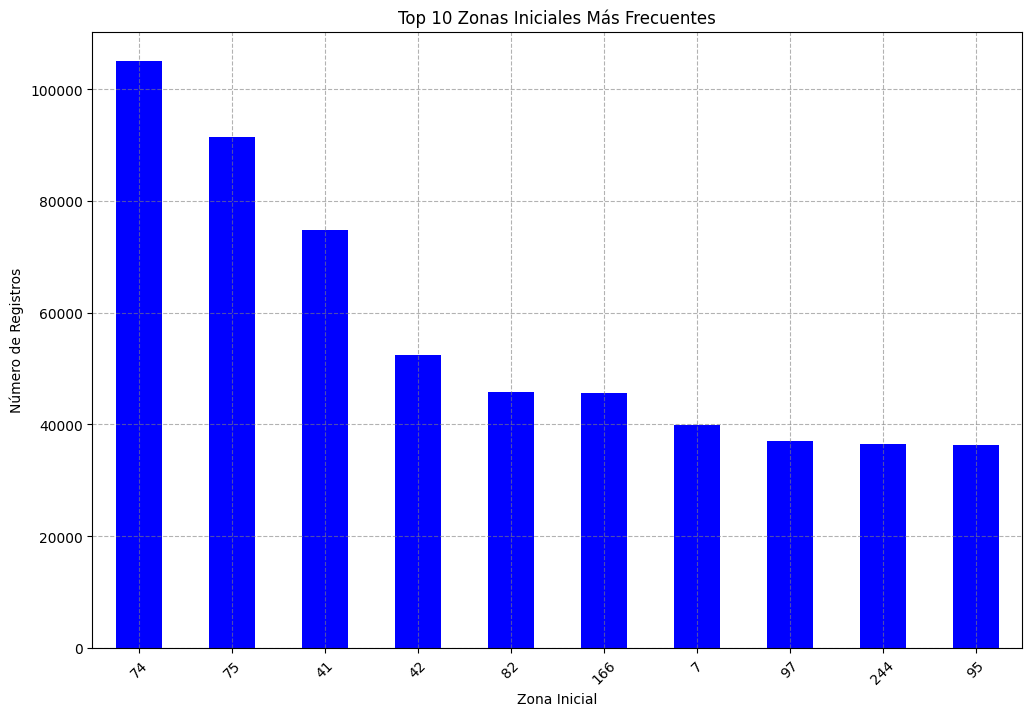

In [ ]:
#Conteo de registros por zona (top 20)
# Contar registros por 'Zona inicial' y seleccionar el top 20
conteoZona = datos2020_1['Zona inicial'].value_counts().nlargest(10)

# Crear gráfico de barras para el top 20
plt.figure(figsize=(12, 8))
conteoZona.plot(kind='bar', color='blue')
plt.title('Top 10 Zonas Iniciales Más Frecuentes')
plt.xlabel('Zona Inicial')
plt.ylabel('Número de Registros')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', which='major', color='grey', alpha=0.6)
plt.show()

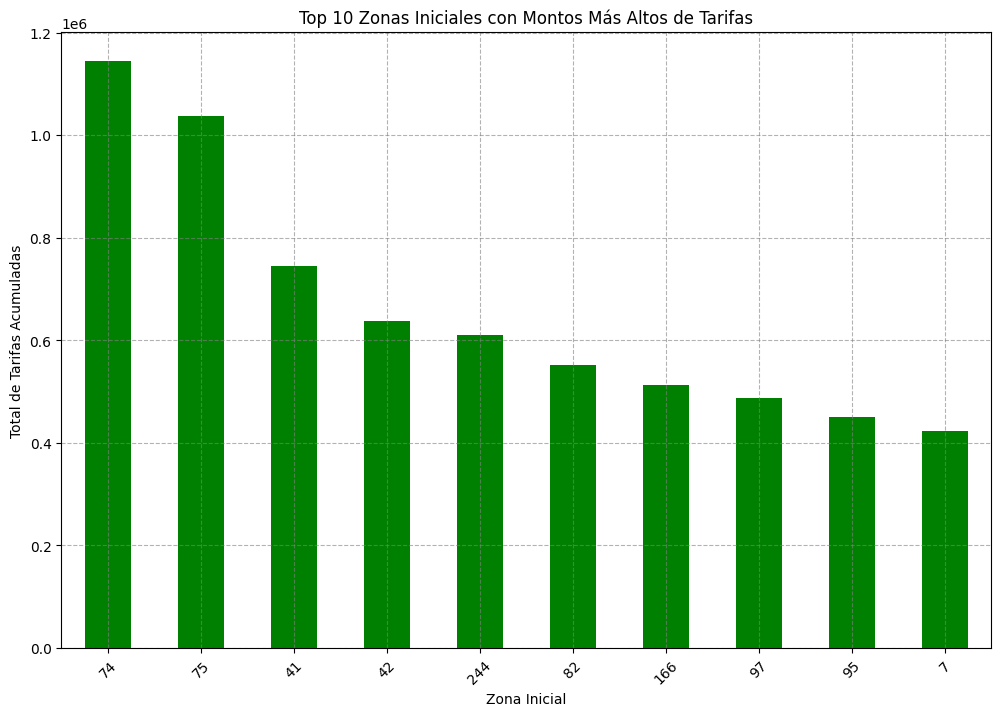

In [ ]:
#Montos totales por zona (top 20)
# Agrupar por 'Zona inicial' y sumar las 'Tarifas'
tarifasZona = datos2020_1.groupby('Zona inicial')['Tarifa'].sum()

# Seleccionar el top 20 de zonas con las tarifas más altas
conteoZona = tarifasZona.nlargest(10)

# Crear gráfico de barras para el top 20 de montos acumulados de tarifa
plt.figure(figsize=(12, 8))
conteoZona.plot(kind='bar', color='green')
plt.title('Top 10 Zonas Iniciales con Montos Más Altos de Tarifas')
plt.xlabel('Zona Inicial')
plt.ylabel('Total de Tarifas Acumuladas')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', which='major', color='grey', alpha=0.6)
plt.show()

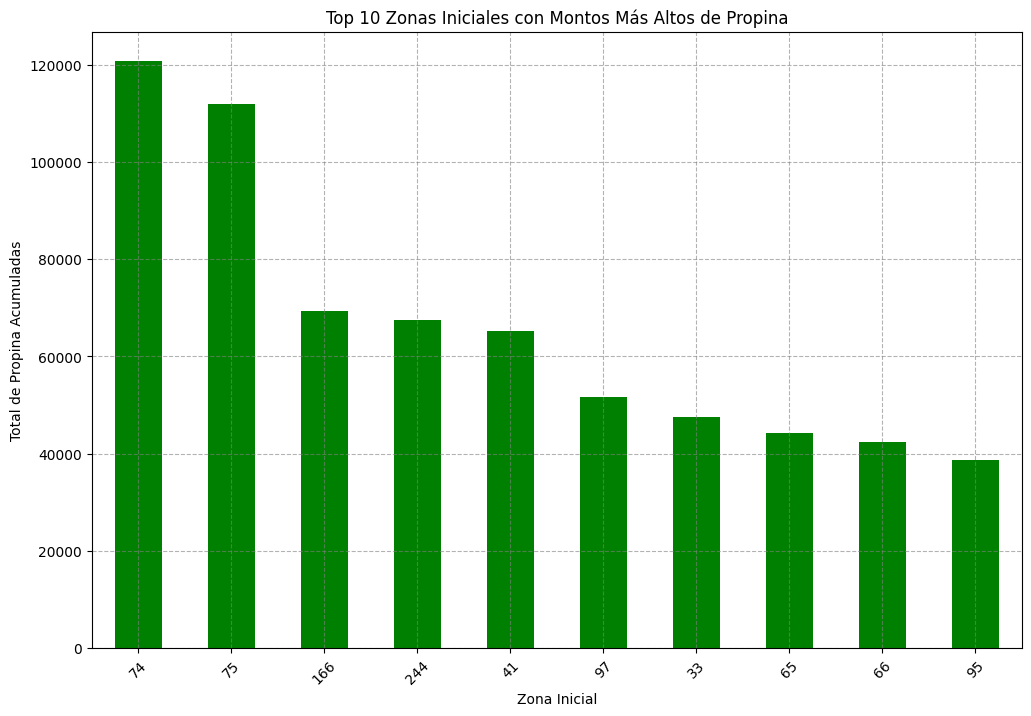

In [ ]:
# Propinas por zona (top 20)
# Agrupar por 'Zona inicial' y sumar las 'Propinas'
propinasZona = datos2020_1.groupby('Zona inicial')['Propina'].sum()

# Seleccionar el top 20 de zonas con las Propina más altas
conteoZona = propinasZona.nlargest(10)

# Crear gráfico de barras para el top 20 de montos acumulados de Propina
plt.figure(figsize=(12, 8))
conteoZona.plot(kind='bar', color='green')
plt.title('Top 10 Zonas Iniciales con Montos Más Altos de Propina')
plt.xlabel('Zona Inicial')
plt.ylabel('Total de Propina Acumuladas')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', which='major', color='grey', alpha=0.6)
plt.show()

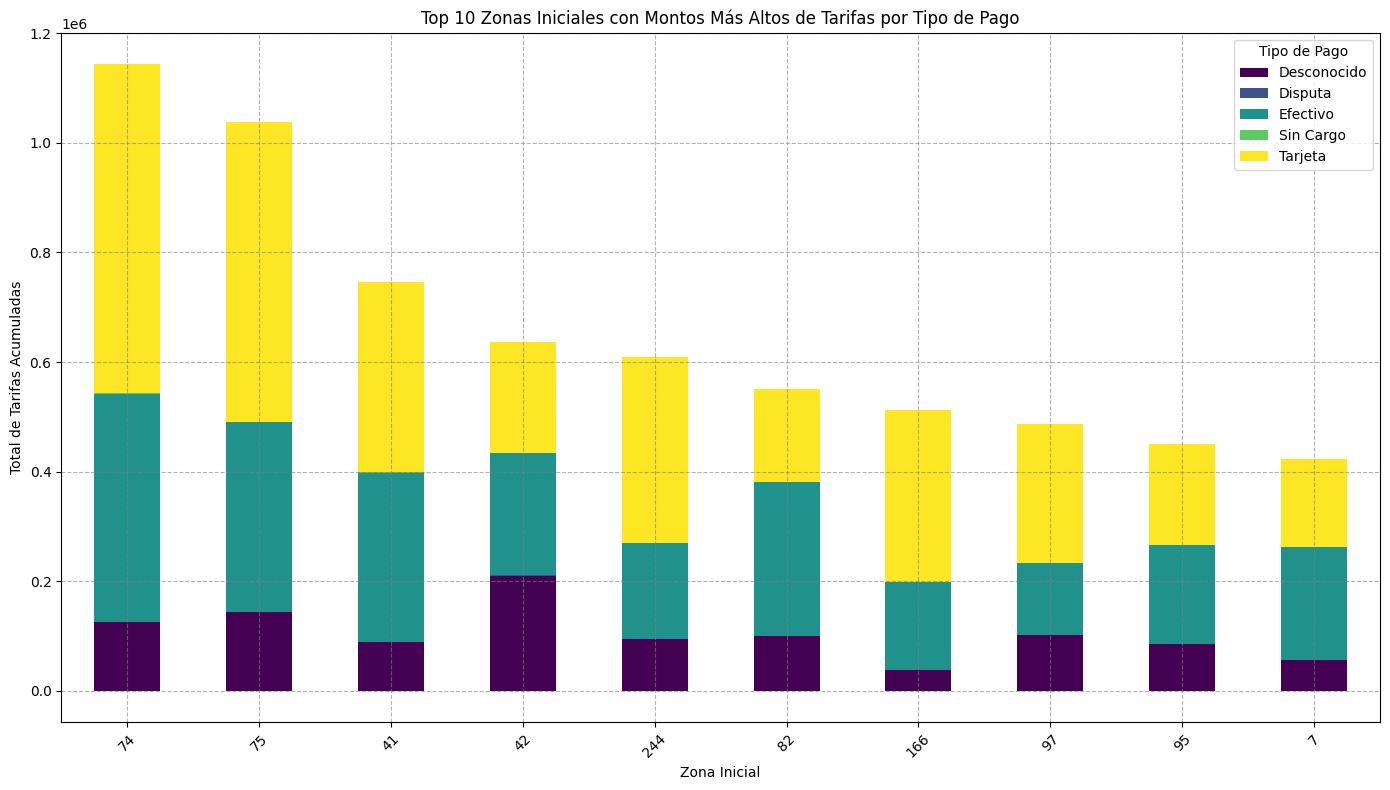

In [ ]:
# montos de tarifa total por tipo de pago y zona, solo es para el top 20 de monto de tarifa recaudado
# Mapeo de 'Tipo de pago' a sus descripciones
tipos_de_pago = {
    1: 'Tarjeta',
    2: 'Efectivo',
    3: 'Sin Cargo',
    4: 'Disputa',
    5: 'Desconocido',
    6: 'Viaje Cancelado'
}
datos2020_1['Tipo de pago'] = datos2020_1['Tipo de pago'].map(tipos_de_pago)

# Agrupar por 'Zona inicial' y 'Tipo de pago', y sumar las 'Tarifas'
sumaPagosZona = datos2020_1.groupby(['Zona inicial', 'Tipo de pago'])['Tarifa'].sum().unstack(fill_value=0)

# Seleccionar las 20 zonas con los montos más altos de tarifas acumuladas
zonasTop = sumaPagosZona.sum(axis=1).nlargest(10).index
topSumaPagosZona = sumaPagosZona.loc[zonasTop]

# Crear gráfico de barras apiladas para el top 20 de montos acumulados de tarifa por tipo de pago
ax = topSumaPagosZona.plot(kind='bar', stacked=True, figsize=(14, 8), colormap='viridis')
plt.title('Top 10 Zonas Iniciales con Montos Más Altos de Tarifas por Tipo de Pago')
plt.xlabel('Zona Inicial')
plt.ylabel('Total de Tarifas Acumuladas')
plt.xticks(rotation=45)
plt.legend(title='Tipo de Pago')
plt.grid(True, linestyle='--', which='major', color='grey', alpha=0.6)
plt.tight_layout()
plt.show()

<ipython-input-20-ceef8d926c68>:15: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-darkgrid')


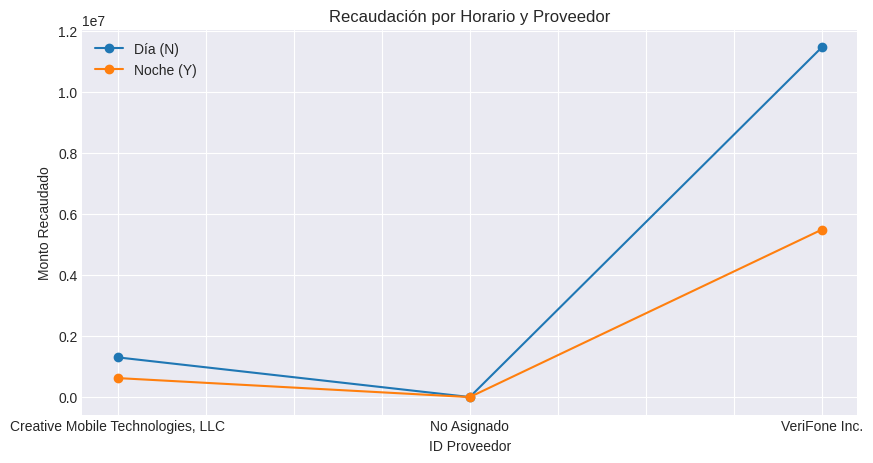

In [ ]:
#Tarifa de noche vs Proveedor vs Tarifa (lineas)
# Diccionario para mapear 'ID Proveedor' a nombres
proveedor_map = {
    1: 'Creative Mobile Technologies, LLC',
    2: 'VeriFone Inc.',
    6: 'No Asignado'
}
# Mapear los nombres de los proveedores en el DataFrame usando el diccionario
datos2020_1['ID Proveedor'] = datos2020_1['ID Proveedor'].map(proveedor_map)

# Agrupar datos por 'ID Proveedor', 'Tarifa noche' y sumar 'Tarifa'
datosAgrupados = datos2020_1.groupby(['ID Proveedor', 'Tarifa noche'])['Tarifa'].sum().unstack(fill_value=0)

# Configurar el estilo del plot (opcional)
plt.style.use('seaborn-darkgrid')

# Crear un gráfico de líneas
datosAgrupados.plot(kind='line', marker='o', figsize=(10, 5))

# Añadir título y etiquetas
plt.title('Recaudación por Horario y Proveedor')
plt.xlabel('ID Proveedor')
plt.ylabel('Monto Recaudado')

# Añadir leyenda
plt.legend(['Día (N)', 'Noche (Y)'])

# Mostrar gráfico
plt.show()

<ipython-input-24-cfaf6a1678ab>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_2020['Fecha inicio'] = pd.to_datetime(df_2020['Fecha inicio'])
<ipython-input-24-cfaf6a1678ab>:12: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-darkgrid')


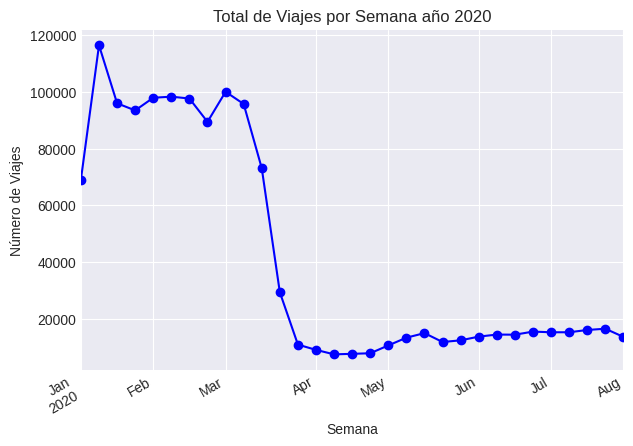

In [ ]:
#total de viajes por semana
# Filtrar los datos para incluir solo los viajes de 2020
df_2020 = datos2020_1[datos2020_1['Fecha inicio'].dt.year == 2020]

# Convertir la columna 'Fecha inicio' a tipo datetime si aún no está convertida
df_2020['Fecha inicio'] = pd.to_datetime(df_2020['Fecha inicio'])

# Agrupar por semana y contar el número de viajes en cada semana
viajesXSemana = df_2020.groupby(pd.Grouper(key='Fecha inicio', freq='W'))['Fecha inicio'].count()

# Configurar el estilo del plot (opcional)
plt.style.use('seaborn-darkgrid')

# Crear el gráfico de líneas
viajesXSemana.plot(kind='line', marker='o', color='blue', figsize=(7, 5))

# Añadir título y etiquetas
plt.title('Total de Viajes por Semana año 2020')
plt.xlabel('Semana')
plt.ylabel('Número de Viajes')

# Ajustar formato de la fecha en el eje x para mejor visualización
plt.gcf().autofmt_xdate()

# Mostrar el gráfico
plt.show()

<ipython-input-23-212f7f72b54f>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_2020['Fecha inicio'] = pd.to_datetime(df_2020['Fecha inicio'])
<ipython-input-23-212f7f72b54f>:12: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-darkgrid')


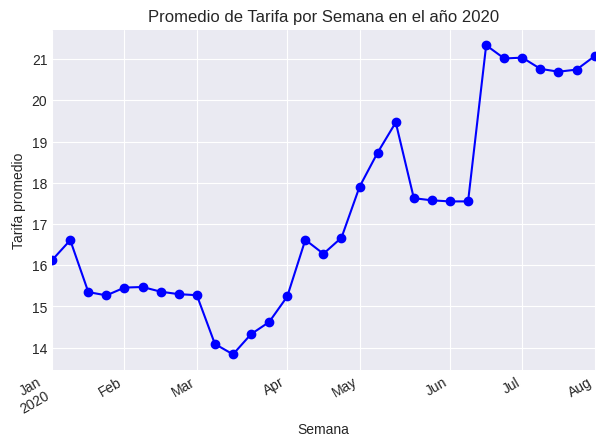

In [ ]:
#promedio de tarifa por semana
# Filtrar los datos para incluir solo los viajes de 2020
df_2020 = datos2020_1[datos2020_1['Fecha inicio'].dt.year == 2020]

# Convertir la columna 'Fecha inicio' a tipo datetime si aún no está convertida
df_2020['Fecha inicio'] = pd.to_datetime(df_2020['Fecha inicio'])

# Agrupar por semana y contar el número de viajes en cada semana
promedioTarifaSemana = df_2020.groupby(pd.Grouper(key='Fecha inicio', freq='W'))['Tarifa'].mean()

# Configurar el estilo del plot (opcional)
plt.style.use('seaborn-darkgrid')

# Crear el gráfico de líneas
promedioTarifaSemana.plot(kind='line', marker='o', color='blue', figsize=(7, 5))

# Añadir título y etiquetas
plt.title('Promedio de Tarifa por Semana en el año 2020')
plt.xlabel('Semana')
plt.ylabel('Tarifa promedio')

# Ajustar formato de la fecha en el eje x para mejor visualización
plt.gcf().autofmt_xdate()

# Mostrar el gráfico
plt.show()